# Task B2: Predicting Wine Critic Scores from Tasting Notes and Metadata

**Student:** Muhammad Ahmad 
**SAP ID:** 70177776 
**Section:** BSRAI-C 
**Course:** AI-101 Introduction to Artificial Intelligence 
**University:** The University of Lahore

---

## Objective

Build a regression model to predict WineEnthusiast critic scores (80–100) from wine metadata 
(price, country, variety) and free-text tasting notes (the `description` field). We compare a 
mean-prediction baseline against Ridge, Linear SVR, and LightGBM, and conduct an ablation study 
to quantify how much the tasting note adds beyond price and origin.

**Primary Metrics:** MAE · RMSE · R²

## 0. Dataset Download Instructions

Download the dataset from Kaggle before running this notebook:

```bash
# Option 1: Kaggle CLI
pip install kaggle
kaggle datasets download -d zynicide/wine-reviews -f winemag-data-130k-v2.csv -p data/

# Option 2: Manual
# Visit https://www.kaggle.com/datasets/zynicide/wine-reviews
# Download winemag-data-130k-v2.csv and place it in data/
```

Expected path: `data/winemag-data-130k-v2.csv`

## 1. Imports & Configuration

In [1]:
# ── Standard library ──
import os
import warnings
warnings.filterwarnings('ignore')

# ── Data handling ──
import numpy as np
import pandas as pd

# ── Visualization ──
import matplotlib.pyplot as plt
import seaborn as sns

# ── Scikit-learn ──
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, SGDRegressor
from sklearn.svm import LinearSVR
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ── LightGBM ──
import lightgbm as lgb

# ── Scipy (sparse matrix ops) ──
from scipy.sparse import issparse, hstack as sparse_hstack

# ── Configuration ──
SEED = 42
np.random.seed(SEED)

FIGURES_DIR = 'figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs('data', exist_ok=True)

# Plot style
sns.set_theme(style='whitegrid', palette='viridis', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.bbox'] = 'tight'

print('All imports loaded successfully.')

All imports loaded successfully.


## 2. Load & Inspect the Data

In [2]:
# Load the raw CSV
raw_df = pd.read_csv('data/winemag-data-130k-v2.csv', index_col=0)
print(f'Raw dataset shape: {raw_df.shape}')
print(f'Columns: {list(raw_df.columns)}')
raw_df.head()

Raw dataset shape: (129971, 13)
Columns: ['country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'taster_name', 'taster_twitter_handle', 'title', 'variety', 'winery']


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [3]:
# Data types and missing values
print('=== Data Types ===')
print(raw_df.dtypes)
print()
print('=== Missing Values ===')
missing = raw_df.isnull().sum()
missing_pct = (missing / len(raw_df) * 100).round(2)
pd.DataFrame({'Missing': missing, 'Percent': missing_pct}).query('Missing > 0').sort_values('Missing', ascending=False)

=== Data Types ===
country                      str
description                  str
designation                  str
points                     int64
price                    float64
province                     str
region_1                     str
region_2                     str
taster_name                  str
taster_twitter_handle        str
title                        str
variety                      str
winery                       str
dtype: object

=== Missing Values ===


,Missing,Percent
region_2,79460,61.14
designation,37465,28.83
taster_twitter_handle,31213,24.02
taster_name,26244,20.19
region_1,21247,16.35
price,8996,6.92
country,63,0.05
province,63,0.05
variety,1,0.00


In [4]:
# Basic statistics for the target and price
raw_df[['points', 'price']].describe()

,points,price
count,129971.000000,120975.000000
mean,88.447138,35.363389
std,3.039730,41.022218
min,80.000000,4.000000
25%,86.000000,17.000000
50%,88.000000,25.000000
75%,91.000000,42.000000
max,100.000000,3300.000000


## 3. De-duplication (Critical Step)

The raw file contains thousands of exact duplicate reviews (same `description`, `title`, 
`points`, `price`, etc.). We **must** remove these **before** splitting to avoid data leakage — 
otherwise, identical reviews could appear in both training and test sets, artificially 
inflating our test metrics.

In [5]:
# Count exact duplicates (across all columns)
n_before = len(raw_df)
n_duplicates = raw_df.duplicated().sum()
print(f'Rows before de-duplication: {n_before:,}')
print(f'Exact duplicate rows found: {n_duplicates:,}')

# Remove exact duplicates
df = raw_df.drop_duplicates().reset_index(drop=True)
n_after = len(df)
print(f'Rows after de-duplication:  {n_after:,}')
print(f'Rows removed:              {n_before - n_after:,}')

Rows before de-duplication: 129,971
Exact duplicate rows found: 9,983
Rows after de-duplication:  119,988
Rows removed:              9,983


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of Points (Target)

Points range: 80 – 100
Mean: 88.44, Std: 3.09


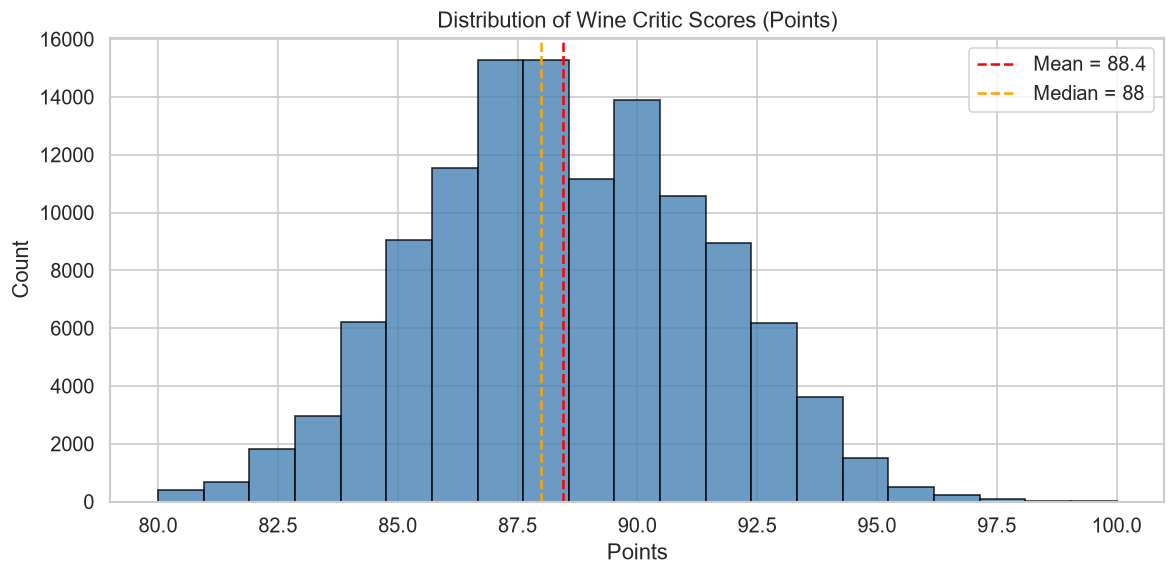

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
df['points'].hist(bins=21, edgecolor='black', alpha=0.8, ax=ax, color='steelblue')
ax.set_xlabel('Points')
ax.set_ylabel('Count')
ax.set_title('Distribution of Wine Critic Scores (Points)')
ax.axvline(df['points'].mean(), color='red', linestyle='--', label=f"Mean = {df['points'].mean():.1f}")
ax.axvline(df['points'].median(), color='orange', linestyle='--', label=f"Median = {df['points'].median():.0f}")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'points_distribution.png'))
plt.show()
print(f"Points range: {df['points'].min()} – {df['points'].max()}")
print(f"Mean: {df['points'].mean():.2f}, Std: {df['points'].std():.2f}")

### 4.2 Distribution of Price and log(Price)

Price — Mean: $35.62, Median: $25.00, Max: $3300
Missing price: 8,395 (7.0%)


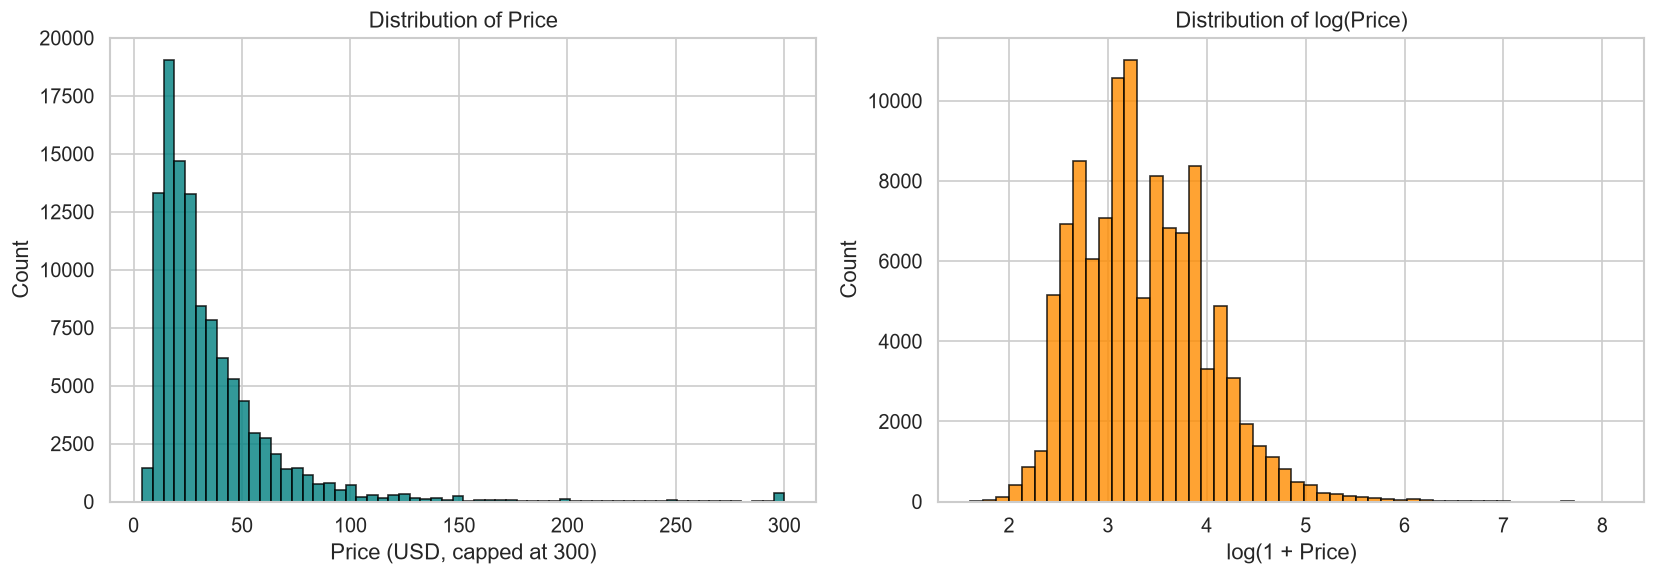

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw price (capped for visibility)
axes[0].hist(df['price'].dropna().clip(upper=300), bins=60, edgecolor='black', alpha=0.8, color='teal')
axes[0].set_xlabel('Price (USD, capped at 300)')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Price')

# Log price
log_price = np.log1p(df['price'].dropna())
axes[1].hist(log_price, bins=50, edgecolor='black', alpha=0.8, color='darkorange')
axes[1].set_xlabel('log(1 + Price)')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of log(Price)')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'price_distribution.png'))
plt.show()

print(f"Price — Mean: ${df['price'].mean():.2f}, Median: ${df['price'].median():.2f}, Max: ${df['price'].max():.0f}")
print(f"Missing price: {df['price'].isnull().sum():,} ({df['price'].isnull().mean()*100:.1f}%)")

### 4.3 Correlation of Points with log(Price)

Pearson correlation (points, log_price): 0.6169


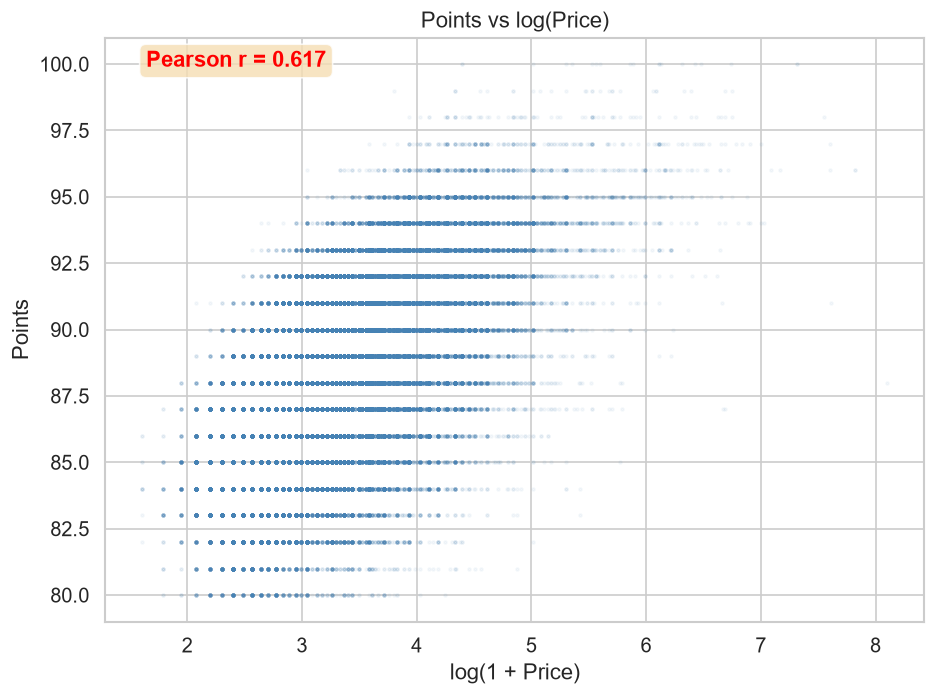

In [8]:
# Compute log(price) for rows with non-null price
price_points = df[['price', 'points']].dropna().copy()
price_points['log_price'] = np.log1p(price_points['price'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(price_points['log_price'], price_points['points'], alpha=0.05, s=3, color='steelblue')
ax.set_xlabel('log(1 + Price)')
ax.set_ylabel('Points')
ax.set_title('Points vs log(Price)')

# Add correlation
corr = price_points['log_price'].corr(price_points['points'])
ax.annotate(f'Pearson r = {corr:.3f}', xy=(0.05, 0.95), xycoords='axes fraction',
            fontsize=13, fontweight='bold', color='red',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'points_vs_log_price.png'))
plt.show()
print(f'Pearson correlation (points, log_price): {corr:.4f}')

### 4.4 Top-10 Countries and Varieties

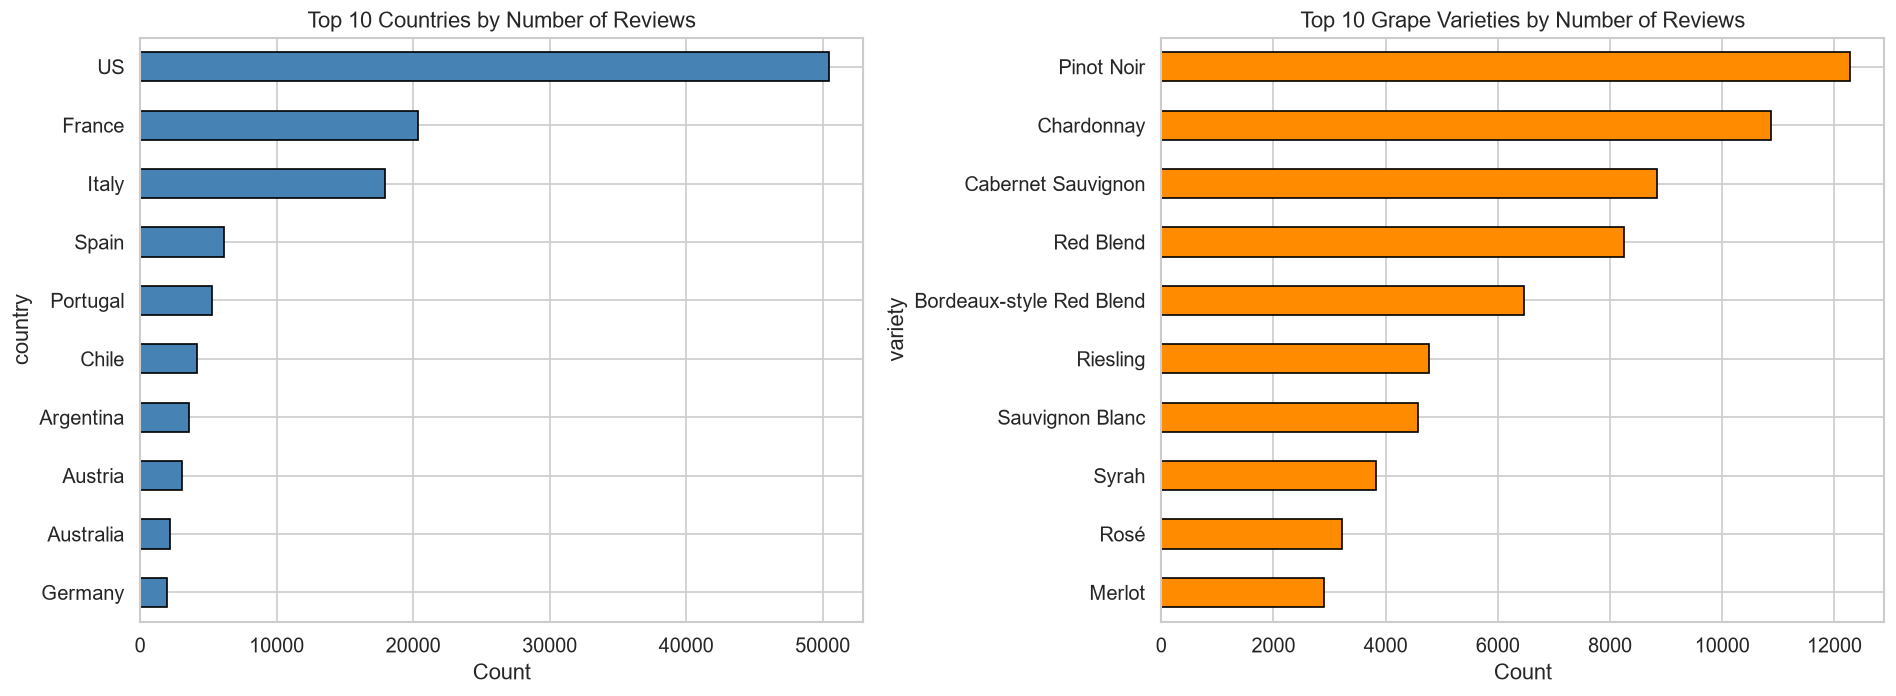

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top-10 countries
top_countries = df['country'].value_counts().head(10)
top_countries.plot.barh(ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Top 10 Countries by Number of Reviews')
axes[0].set_xlabel('Count')
axes[0].invert_yaxis()

# Top-10 varieties
top_varieties = df['variety'].value_counts().head(10)
top_varieties.plot.barh(ax=axes[1], color='darkorange', edgecolor='black')
axes[1].set_title('Top 10 Grape Varieties by Number of Reviews')
axes[1].set_xlabel('Count')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'top10_countries_varieties.png'))
plt.show()

### 4.5 Description Length vs Points

Correlation (description length, points): 0.5622


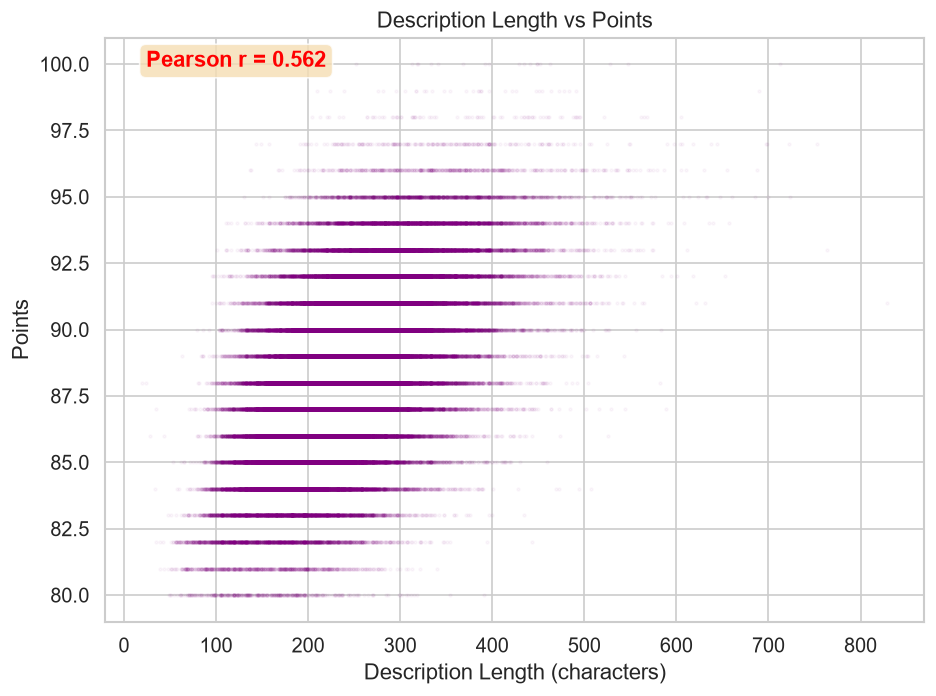

In [10]:
df['desc_length'] = df['description'].fillna('').str.len()

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df['desc_length'], df['points'], alpha=0.03, s=3, color='purple')
ax.set_xlabel('Description Length (characters)')
ax.set_ylabel('Points')
ax.set_title('Description Length vs Points')

corr_len = df['desc_length'].corr(df['points'])
ax.annotate(f'Pearson r = {corr_len:.3f}', xy=(0.05, 0.95), xycoords='axes fraction',
            fontsize=13, fontweight='bold', color='red',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'desc_length_vs_points.png'))
plt.show()
print(f'Correlation (description length, points): {corr_len:.4f}')

### 4.6 Points by Country (Box Plot — Top 10)

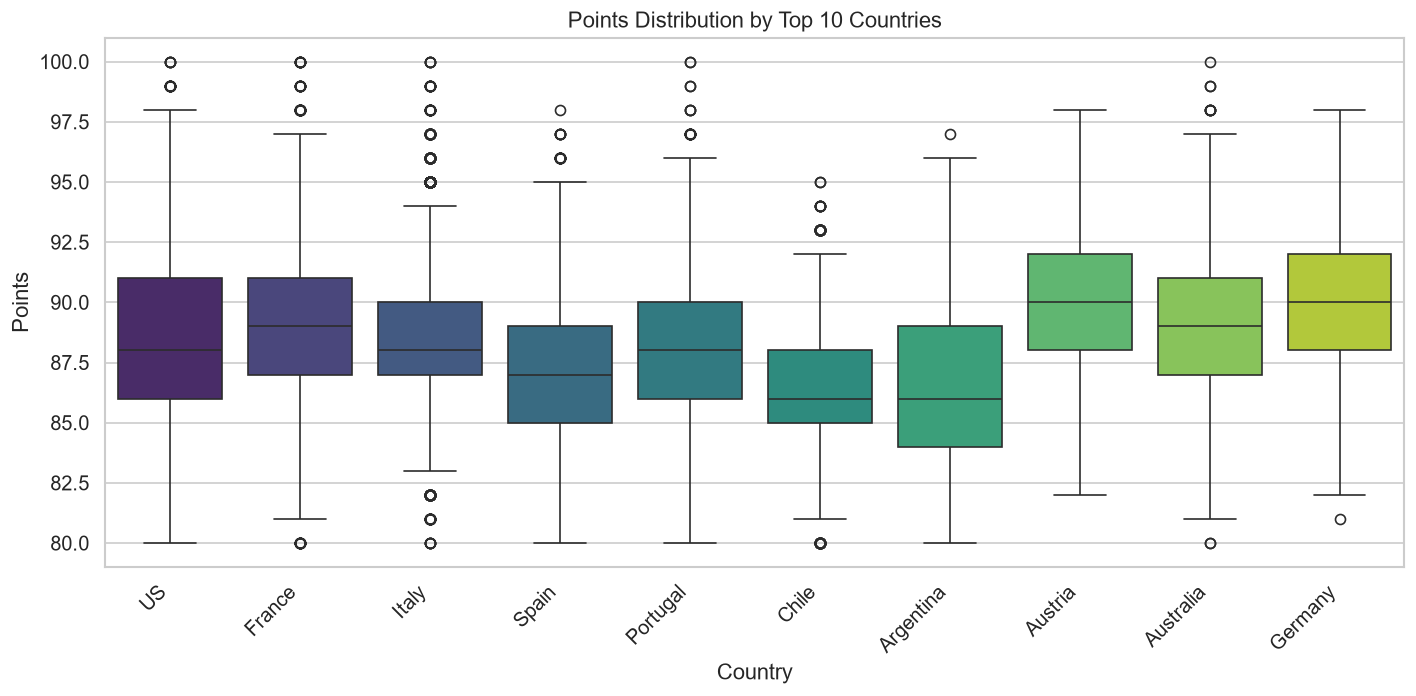

In [11]:
top10_list = df['country'].value_counts().head(10).index.tolist()
df_top10 = df[df['country'].isin(top10_list)]

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df_top10, x='country', y='points', order=top10_list, ax=ax, palette='viridis')
ax.set_xlabel('Country')
ax.set_ylabel('Points')
ax.set_title('Points Distribution by Top 10 Countries')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'points_by_country_boxplot.png'))
plt.show()

## 5. Feature Engineering

We engineer three groups of features:

1. **Numeric**: `log(1 + price)` with median imputation + a binary `price_missing` indicator
2. **Categorical**: One-hot encoding of `country`, `province`, `variety` (top-N, rest → "Other")
3. **Text**: TF-IDF on the `description` field (tasting notes)

In [12]:
# ── Prepare features ──

# 5a. Numeric: log(price) + missing indicator
df['log_price'] = np.log1p(df['price'])
df['price_missing'] = df['price'].isnull().astype(int)

# 5b. Categorical: group rare categories as "Other"
def group_rare(series, top_n=20):
    """Keep top_n most frequent values, group rest as 'Other'."""
    top_vals = series.value_counts().head(top_n).index
    return series.where(series.isin(top_vals), other='Other').fillna('Unknown')

df['country_clean'] = group_rare(df['country'], top_n=15)
df['province_clean'] = group_rare(df['province'], top_n=20)
df['variety_clean'] = group_rare(df['variety'], top_n=25)

# 5c. Text: ensure description is a string
df['description'] = df['description'].fillna('')

# Clean up the temporary EDA column
df.drop(columns=['desc_length'], inplace=True, errors='ignore')

print('Feature engineering complete.')
print(f"Unique countries (cleaned): {df['country_clean'].nunique()}")
print(f"Unique provinces (cleaned): {df['province_clean'].nunique()}")
print(f"Unique varieties (cleaned): {df['variety_clean'].nunique()}")

Feature engineering complete.
Unique countries (cleaned): 16
Unique provinces (cleaned): 21
Unique varieties (cleaned): 26


## 6. Train / Validation / Test Split (80 / 10 / 10)

We split **after** de-duplication to ensure no data leakage.

In [13]:
# Define target and feature columns
TARGET = 'points'

NUMERIC_COLS = ['log_price', 'price_missing']
CAT_COLS = ['country_clean', 'province_clean', 'variety_clean']
TEXT_COL = 'description'

y = df[TARGET].values

# First split: 80% train, 20% temp
train_idx, temp_idx = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=SEED
)

# Second split: 50/50 of temp → 10% val, 10% test
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED
)

df_train = df.iloc[train_idx].reset_index(drop=True)
df_val   = df.iloc[val_idx].reset_index(drop=True)
df_test  = df.iloc[test_idx].reset_index(drop=True)

y_train = y[train_idx]
y_val   = y[val_idx]
y_test  = y[test_idx]

print(f'Train: {len(df_train):,}  |  Val: {len(df_val):,}  |  Test: {len(df_test):,}')
print(f'Total: {len(df_train)+len(df_val)+len(df_test):,}')

Train: 95,990  |  Val: 11,999  |  Test: 11,999
Total: 119,988


## 7. Build Preprocessing Pipelines with ColumnTransformer

We build three feature sets:
- **Metadata-only**: numeric + categorical
- **Text-only**: TF-IDF on description
- **Combined**: all three

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin


class LogPriceImputer(BaseEstimator, TransformerMixin):
    """Impute missing log_price with the training median."""
    def fit(self, X, y=None):
        self.median_ = np.nanmedian(X)
        return self
    def transform(self, X):
        X_out = X.copy()
        X_out[np.isnan(X_out)] = self.median_
        return X_out.reshape(-1, 1)


# ── Numeric transformer: impute log_price, pass price_missing through ──
numeric_transformer = ColumnTransformer(
    transformers=[
        ('log_price_impute', make_pipeline(
            SimpleImputer(strategy='median')
        ), ['log_price']),
        ('price_missing', 'passthrough', ['price_missing']),
    ]
)

# ── Categorical transformer: one-hot encode ──
cat_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=True)

# ── Text transformer: TF-IDF ──
tfidf_transformer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95,
    sublinear_tf=True,
    stop_words='english'
)

# ── Combined preprocessor ──
preprocessor_combined = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, NUMERIC_COLS),
        ('cat', cat_transformer, CAT_COLS),
        ('text', tfidf_transformer, TEXT_COL),
    ],
    remainder='drop'
)

# ── Metadata-only preprocessor (no text) ──
preprocessor_metadata = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, NUMERIC_COLS),
        ('cat', cat_transformer, CAT_COLS),
    ],
    remainder='drop'
)

# ── Text-only preprocessor ──
preprocessor_text = ColumnTransformer(
    transformers=[
        ('text', tfidf_transformer, TEXT_COL),
    ],
    remainder='drop'
)

print('Preprocessors defined.')

Preprocessors defined.


## 8. Model Training & Evaluation

We train four models for each feature set (combined, metadata-only, text-only):

| # | Model | Description |
|---|-------|-------------|
| 0 | Baseline | Always predicts the training mean |
| 1 | Ridge | Linear regression with L2 regularization |
| 2 | LinearSVR | Support Vector Regression (linear kernel) |
| 3 | LightGBM | Gradient Boosted Decision Trees |

In [15]:
def evaluate(y_true, y_pred, label=''):
    """Compute and return MAE, RMSE, R² as a dict."""
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    return {'Model': label, 'MAE': round(mae, 4), 'RMSE': round(rmse, 4), 'R²': round(r2, 4)}


def train_and_evaluate_all(preprocessor, df_train, df_val, df_test,
                           y_train, y_val, y_test, feature_set_name):
    """
    Train all four models on the given feature set.
    Returns a list of result dicts and a dict of fitted pipelines.
    """
    results = []
    pipelines = {}
    
    models = {
        'Baseline (Mean)': DummyRegressor(strategy='mean'),
        'Ridge': Ridge(alpha=1.0, random_state=SEED),
        'LinearSVR': LinearSVR(max_iter=2000, random_state=SEED, dual='auto'),
        'LightGBM': lgb.LGBMRegressor(
            n_estimators=250,
            learning_rate=0.05,
            max_depth=7,
            num_leaves=63,
            min_child_samples=20,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=SEED,
            verbose=-1,
            n_jobs=-1,
        ),
    }
    
    for name, model in models.items():
        label = f'{name} ({feature_set_name})'
        print(f'  Training {label}...')
        
        pipe = Pipeline([
            ('preprocess', preprocessor),
            ('model', model)
        ])
        
        pipe.fit(df_train, y_train)
        
        # Evaluate on test set
        y_pred_test = pipe.predict(df_test)
        res = evaluate(y_test, y_pred_test, label)
        results.append(res)
        pipelines[name] = pipe
        
        print(f'    Test — MAE: {res["MAE"]:.4f}  RMSE: {res["RMSE"]:.4f}  R²: {res["R²"]:.4f}')
    
    return results, pipelines

print('Evaluation functions defined.')


Evaluation functions defined.


### 8.1 Combined Features (Metadata + Text)

In [16]:
print('=== COMBINED (Metadata + Text) ===')
results_combined, pipes_combined = train_and_evaluate_all(
    preprocessor_combined, df_train, df_val, df_test,
    y_train, y_val, y_test, 'Combined'
)

=== COMBINED (Metadata + Text) ===
  Training Baseline (Mean) (Combined)...
    Test — MAE: 2.5290  RMSE: 3.0923  R²: -0.0000
  Training Ridge (Combined)...
    Test — MAE: 1.1875  RMSE: 1.5211  R²: 0.7580
  Training LinearSVR (Combined)...
    Test — MAE: 1.2030  RMSE: 1.5454  R²: 0.7502
  Training LightGBM (Combined)...
    Test — MAE: 1.4006  RMSE: 1.7867  R²: 0.6662


### 8.2 Metadata-Only Features

In [17]:
print('=== METADATA ONLY ===')
results_metadata, pipes_metadata = train_and_evaluate_all(
    preprocessor_metadata, df_train, df_val, df_test,
    y_train, y_val, y_test, 'Metadata'
)

=== METADATA ONLY ===
  Training Baseline (Mean) (Metadata)...
    Test — MAE: 2.5290  RMSE: 3.0923  R²: -0.0000
  Training Ridge (Metadata)...
    Test — MAE: 1.8987  RMSE: 2.3852  R²: 0.4050
  Training LinearSVR (Metadata)...
    Test — MAE: 1.8924  RMSE: 2.3961  R²: 0.3996
  Training LightGBM (Metadata)...
    Test — MAE: 1.8429  RMSE: 2.3198  R²: 0.4372


### 8.3 Text-Only Features

In [18]:
print('=== TEXT ONLY ===')
results_text, pipes_text = train_and_evaluate_all(
    preprocessor_text, df_train, df_val, df_test,
    y_train, y_val, y_test, 'Text'
)

=== TEXT ONLY ===
  Training Baseline (Mean) (Text)...
    Test — MAE: 2.5290  RMSE: 3.0923  R²: -0.0000
  Training Ridge (Text)...
    Test — MAE: 1.3322  RMSE: 1.6941  R²: 0.6999
  Training LinearSVR (Text)...
    Test — MAE: 1.3458  RMSE: 1.7156  R²: 0.6922
  Training LightGBM (Text)...
    Test — MAE: 1.6148  RMSE: 2.0456  R²: 0.5624


## 9. Results Summary — All Models × All Feature Sets

In [19]:
# Compile all results into a single DataFrame
all_results = results_combined + results_metadata + results_text
results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values('MAE').reset_index(drop=True)

print('\n' + '='*80)
print('           TEST SET RESULTS — ALL MODELS × ALL FEATURE SETS')
print('='*80)
print(results_df.to_string(index=False))
print('='*80)


           TEST SET RESULTS — ALL MODELS × ALL FEATURE SETS
                     Model    MAE   RMSE      R²
          Ridge (Combined) 1.1875 1.5211  0.7580
      LinearSVR (Combined) 1.2030 1.5454  0.7502
              Ridge (Text) 1.3322 1.6941  0.6999
          LinearSVR (Text) 1.3458 1.7156  0.6922
       LightGBM (Combined) 1.4006 1.7867  0.6662
           LightGBM (Text) 1.6148 2.0456  0.5624
       LightGBM (Metadata) 1.8429 2.3198  0.4372
      LinearSVR (Metadata) 1.8924 2.3961  0.3996
          Ridge (Metadata) 1.8987 2.3852  0.4050
Baseline (Mean) (Combined) 2.5290 3.0923 -0.0000
Baseline (Mean) (Metadata) 2.5290 3.0923 -0.0000
    Baseline (Mean) (Text) 2.5290 3.0923 -0.0000


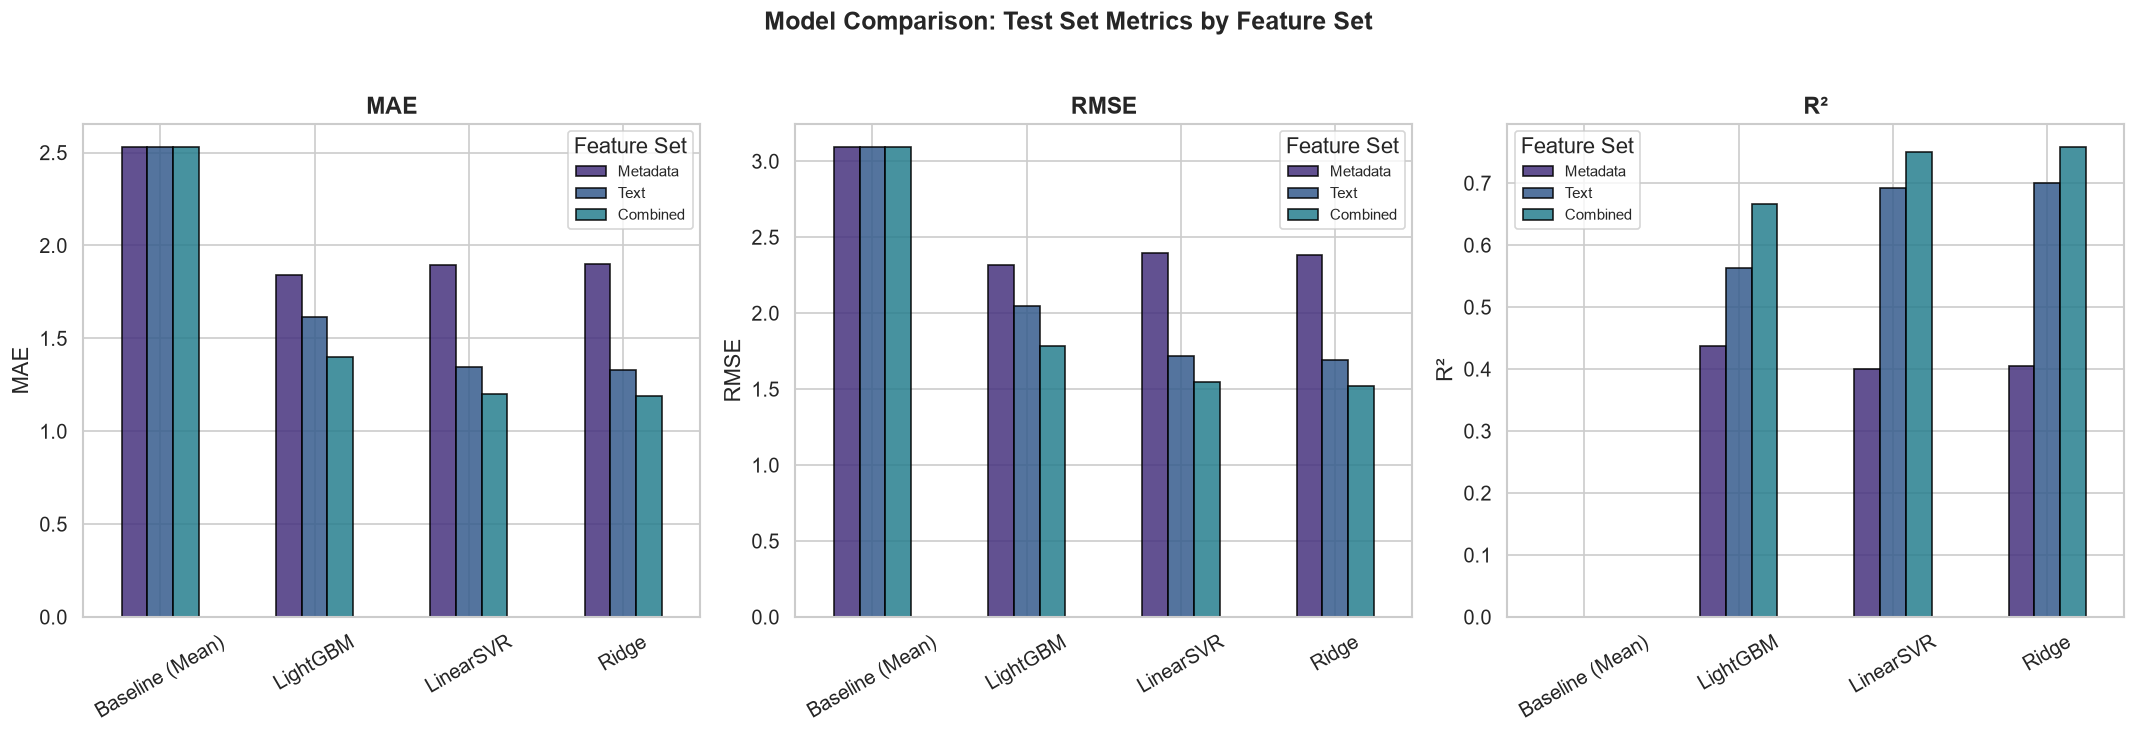

In [20]:
# Visualize the comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, metric in enumerate(['MAE', 'RMSE', 'R²']):
    ax = axes[i]
    pivot = results_df.copy()
    pivot['ModelName'] = pivot['Model'].apply(lambda x: x.rsplit(' (', 1)[0] if ' (' in x else x)
    pivot['FeatureSet'] = pivot['Model'].apply(lambda x: x.rsplit(' (', 1)[1].rstrip(')') if ' (' in x else '')
    piv = pivot.pivot_table(index='ModelName', columns='FeatureSet', values=metric, aggfunc='first')
    piv = piv.reindex(columns=['Metadata', 'Text', 'Combined'])
    piv.plot.bar(ax=ax, edgecolor='black', alpha=0.85)
    ax.set_title(metric, fontsize=14, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)
    ax.legend(title='Feature Set', fontsize=9)

plt.suptitle('Model Comparison: Test Set Metrics by Feature Set', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'model_comparison_bar.png'))
plt.show()


## 10. Ablation Analysis

**Ablation Table:** How much does each feature group contribute?

In [21]:
# For each model, compare metadata-only → combined to see text's contribution
print('\n=== ABLATION: Metadata-only → Combined (Ridge) ===')
for model_name in ['Ridge', 'LinearSVR', 'LightGBM']:
    meta_res = [r for r in results_metadata if model_name in r['Model']][0]
    text_res = [r for r in results_text if model_name in r['Model']][0]
    comb_res = [r for r in results_combined if model_name in r['Model']][0]
    
    print(f'\n{model_name}:')
    print(f'  Metadata-only  MAE = {meta_res["MAE"]:.4f}  R² = {meta_res["R²"]:.4f}')
    print(f'  Text-only      MAE = {text_res["MAE"]:.4f}  R² = {text_res["R²"]:.4f}')
    print(f'  Combined       MAE = {comb_res["MAE"]:.4f}  R² = {comb_res["R²"]:.4f}')
    print(f'  → Adding text to metadata reduces MAE by {meta_res["MAE"] - comb_res["MAE"]:.4f}')
    print(f'  → Adding text to metadata improves R² by {comb_res["R²"] - meta_res["R²"]:.4f}')


=== ABLATION: Metadata-only → Combined (Ridge) ===

Ridge:
  Metadata-only  MAE = 1.8987  R² = 0.4050
  Text-only      MAE = 1.3322  R² = 0.6999
  Combined       MAE = 1.1875  R² = 0.7580
  → Adding text to metadata reduces MAE by 0.7112
  → Adding text to metadata improves R² by 0.3530

LinearSVR:
  Metadata-only  MAE = 1.8924  R² = 0.3996
  Text-only      MAE = 1.3458  R² = 0.6922
  Combined       MAE = 1.2030  R² = 0.7502
  → Adding text to metadata reduces MAE by 0.6894
  → Adding text to metadata improves R² by 0.3506

LightGBM:
  Metadata-only  MAE = 1.8429  R² = 0.4372
  Text-only      MAE = 1.6148  R² = 0.5624
  Combined       MAE = 1.4006  R² = 0.6662
  → Adding text to metadata reduces MAE by 0.4423
  → Adding text to metadata improves R² by 0.2290


## 11. Detailed Analysis of Best Model

### 11.1 Residual Plot

Mean residual: 0.0285
Std of residuals: 1.7865


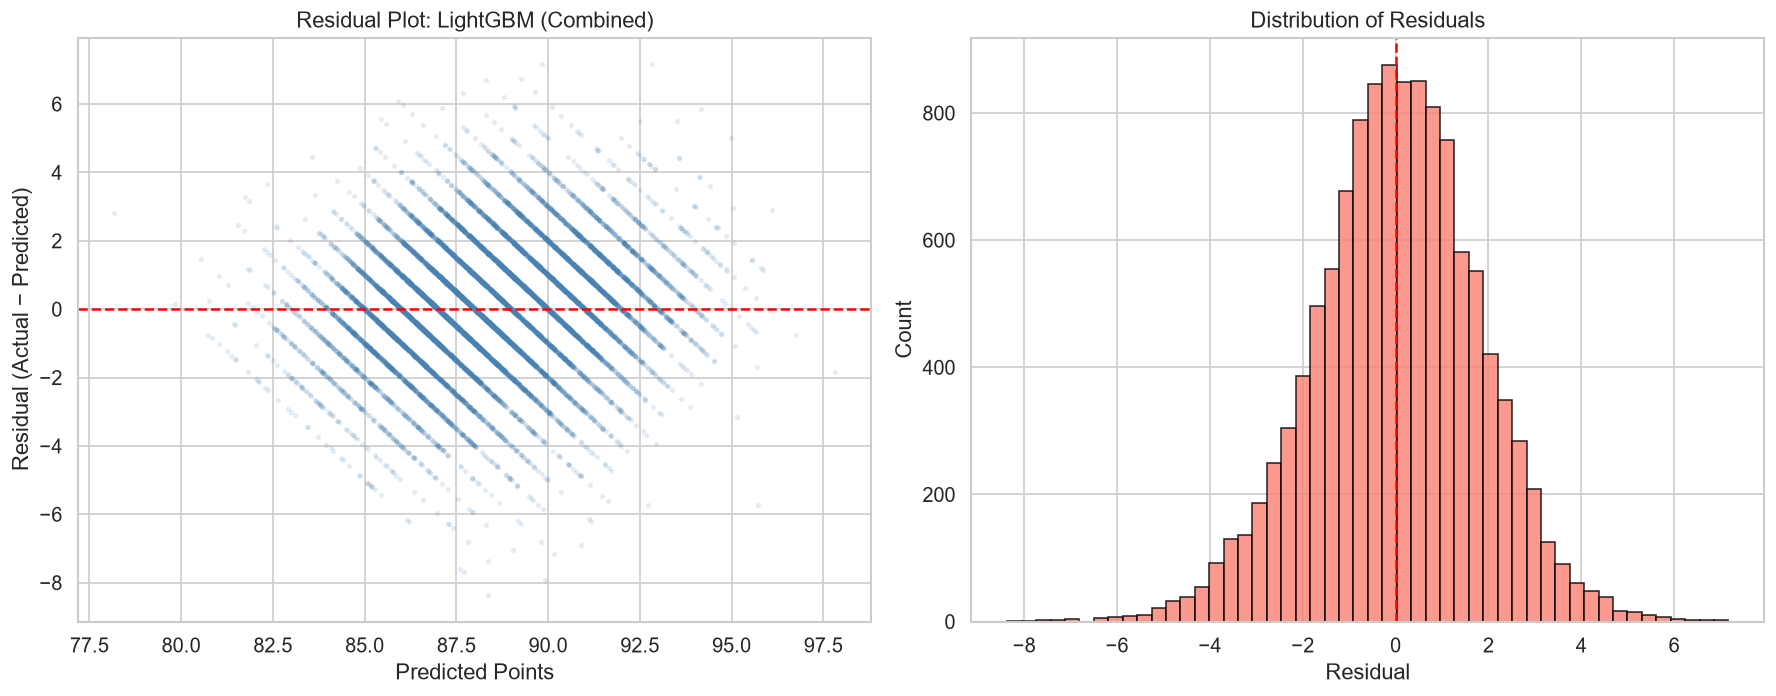

In [22]:
# Use LightGBM Combined as the best model
best_pipe = pipes_combined['LightGBM']
y_pred_best = best_pipe.predict(df_test)
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Residual vs Predicted
axes[0].scatter(y_pred_best, residuals, alpha=0.1, s=5, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Predicted Points')
axes[0].set_ylabel('Residual (Actual − Predicted)')
axes[0].set_title('Residual Plot: LightGBM (Combined)')

# Residual histogram
axes[1].hist(residuals, bins=50, edgecolor='black', alpha=0.8, color='salmon')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of Residuals')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'residual_plot.png'))
plt.show()

print(f'Mean residual: {residuals.mean():.4f}')
print(f'Std of residuals: {residuals.std():.4f}')

### 11.2 MAE per Points Band


MAE per Points Band (LightGBM Combined):
  Band    N    MAE  Mean Actual  Mean Predicted
 80–84 1216 2.2370        83.14           85.30
 85–89 6248 1.1522        87.15           87.56
 90–94 4299 1.4477        91.42           90.28
95–100  236 2.8113        95.66           92.89


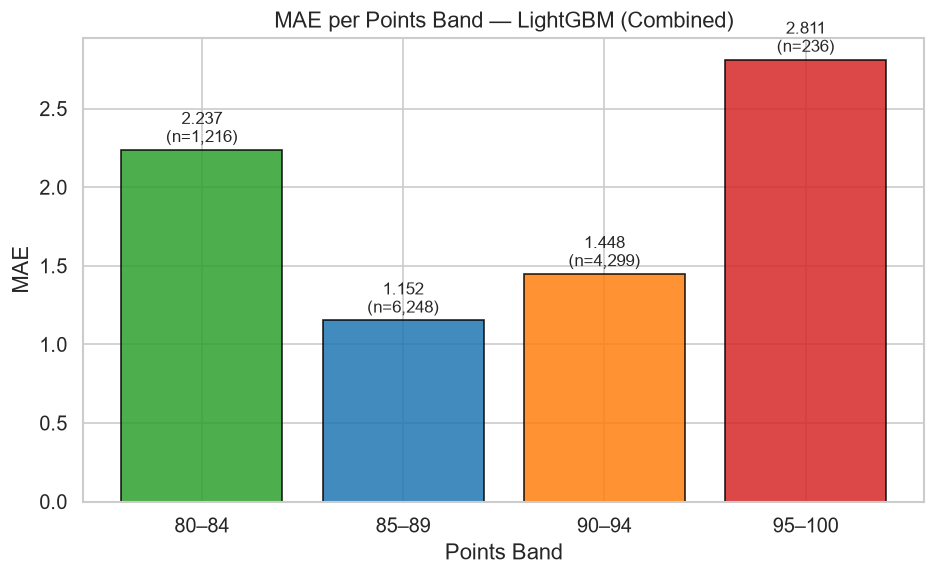

In [23]:
# Define points bands
bands = [
    ('80–84', (80, 84)),
    ('85–89', (85, 89)),
    ('90–94', (90, 94)),
    ('95–100', (95, 100)),
]

band_results = []
for band_name, (lo, hi) in bands:
    mask = (y_test >= lo) & (y_test <= hi)
    n_band = mask.sum()
    if n_band > 0:
        mae_band = mean_absolute_error(y_test[mask], y_pred_best[mask])
        band_results.append({
            'Band': band_name,
            'N': n_band,
            'MAE': round(mae_band, 4),
            'Mean Actual': round(y_test[mask].mean(), 2),
            'Mean Predicted': round(y_pred_best[mask].mean(), 2),
        })

band_df = pd.DataFrame(band_results)
print('\nMAE per Points Band (LightGBM Combined):')
print(band_df.to_string(index=False))

# Bar chart
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']
ax.bar(band_df['Band'], band_df['MAE'], color=colors, edgecolor='black', alpha=0.85)
ax.set_xlabel('Points Band')
ax.set_ylabel('MAE')
ax.set_title('MAE per Points Band — LightGBM (Combined)')
for i, row in band_df.iterrows():
    ax.text(i, row['MAE'] + 0.02, f"{row['MAE']:.3f}\n(n={row['N']:,})",
            ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'mae_per_band.png'))
plt.show()

## 12. Ridge Coefficient Analysis — Which Words Push Scores Up or Down?

We examine the TF-IDF feature coefficients from the Ridge regression (Combined) to find 
the most influential words.

In [24]:
# Extract Ridge (Combined) pipeline
ridge_pipe = pipes_combined['Ridge']
ridge_model = ridge_pipe.named_steps['model']
ct = ridge_pipe.named_steps['preprocess']

# Get feature names from the ColumnTransformer
feature_names = ct.get_feature_names_out()
coefficients = ridge_model.coef_

# Create a DataFrame of features and their coefficients
coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})

# Filter to TF-IDF features only
text_coef = coef_df[coef_df['feature'].str.startswith('text__')].copy()
text_coef['word'] = text_coef['feature'].str.replace('text__', '', regex=False)
text_coef = text_coef.sort_values('coefficient')

print(f'Total text features: {len(text_coef):,}')
print()

# Top 20 positive (push scores UP)
print('=== Top 20 Words That INCREASE Predicted Score ===')
top_pos = text_coef.tail(20).sort_values('coefficient', ascending=False)
for _, row in top_pos.iterrows():
    print(f"  {row['word']:30s}  coef = {row['coefficient']:+.4f}")

print()
print('=== Top 20 Words That DECREASE Predicted Score ===')
top_neg = text_coef.head(20)
for _, row in top_neg.iterrows():
    print(f"  {row['word']:30s}  coef = {row['coefficient']:+.4f}")

Total text features: 10,000

=== Top 20 Words That INCREASE Predicted Score ===
  gorgeous                        coef = +7.3219
  superb                          coef = +7.1109
  94                              coef = +6.8187
  delicious                       coef = +6.6349
  beautiful                       coef = +6.2468
  stunning                        coef = +5.9774
  tremendous                      coef = +5.9442
  years                           coef = +5.8510
  complex                         coef = +5.7900
  extraordinary                   coef = +5.7450
  amazingly                       coef = +5.7099
  stunner                         coef = +5.5208
  spectacular                     coef = +5.4546
  beautifully                     coef = +5.4431
  impressive                      coef = +5.3917
  wonderful                       coef = +5.3849
  barrel sample                   coef = +5.2829
  brilliant                       coef = +5.2443
  rich                            coef

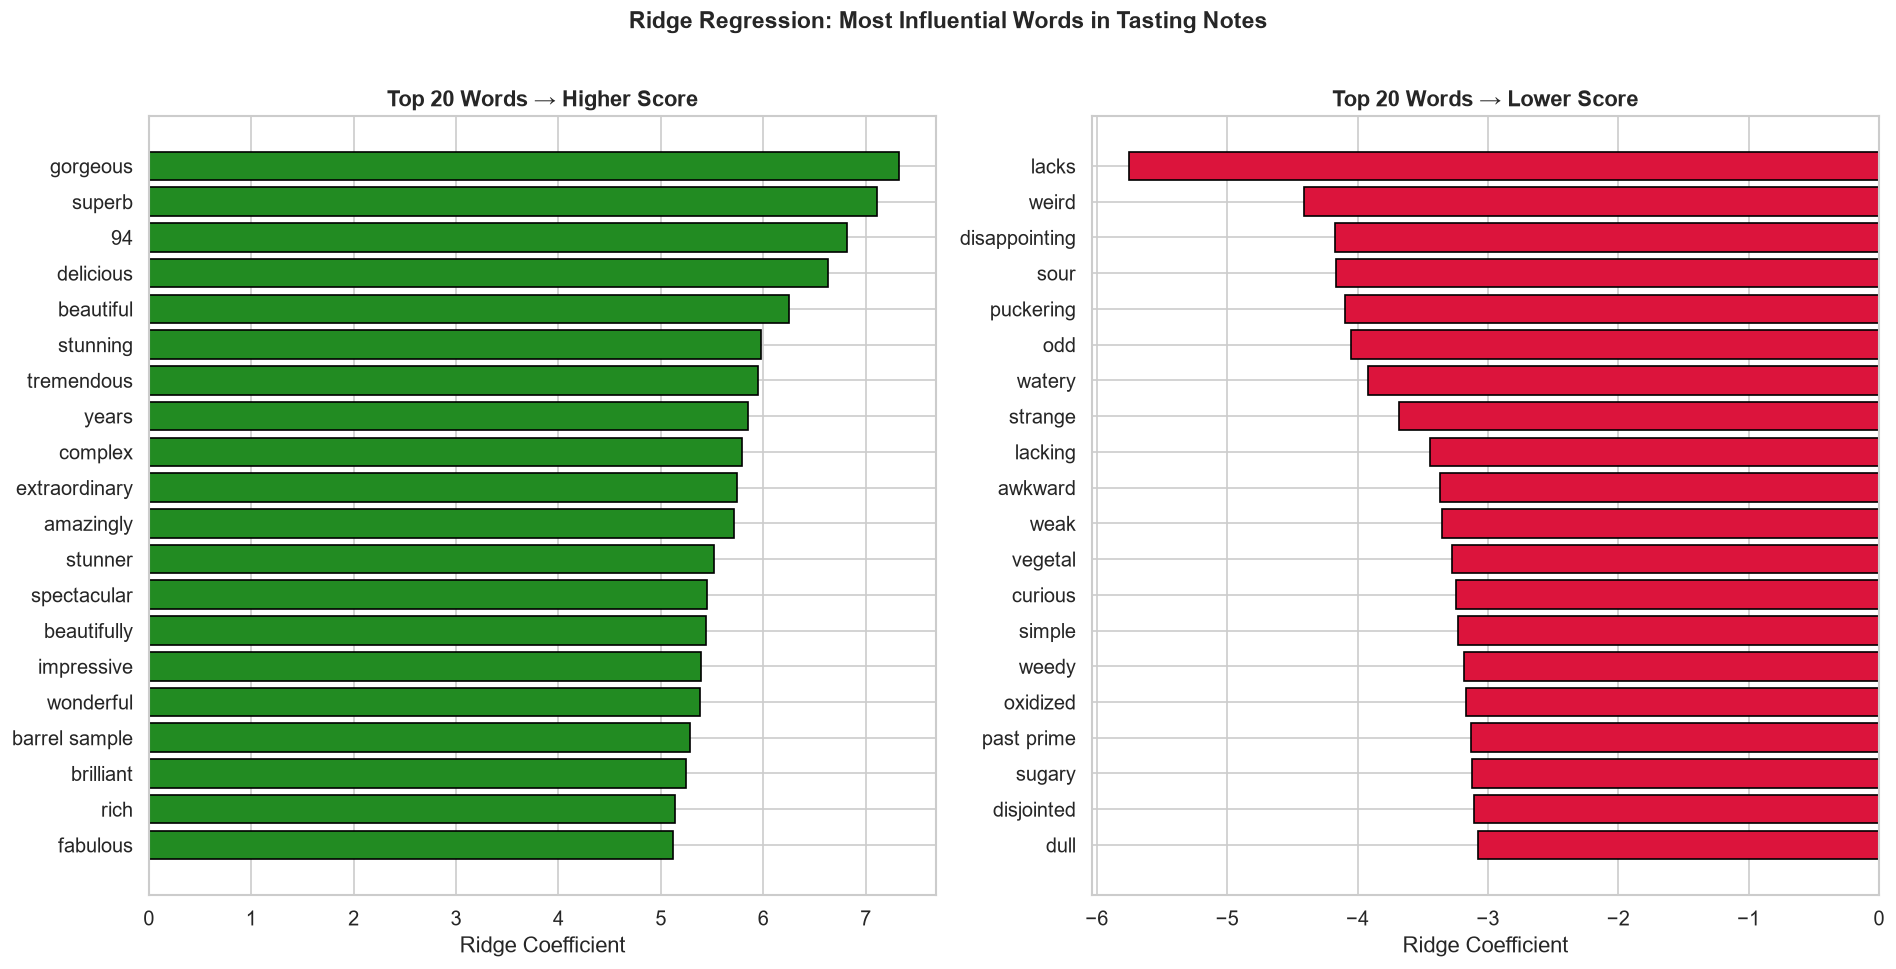

In [25]:
# Visualize top/bottom words
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Top 20 positive
top20_pos = text_coef.nlargest(20, 'coefficient')
axes[0].barh(top20_pos['word'], top20_pos['coefficient'], color='forestgreen', edgecolor='black')
axes[0].set_xlabel('Ridge Coefficient')
axes[0].set_title('Top 20 Words → Higher Score', fontweight='bold')
axes[0].invert_yaxis()

# Top 20 negative
top20_neg = text_coef.nsmallest(20, 'coefficient')
axes[1].barh(top20_neg['word'], top20_neg['coefficient'], color='crimson', edgecolor='black')
axes[1].set_xlabel('Ridge Coefficient')
axes[1].set_title('Top 20 Words → Lower Score', fontweight='bold')
axes[1].invert_yaxis()

plt.suptitle('Ridge Regression: Most Influential Words in Tasting Notes', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'ridge_word_coefficients.png'))
plt.show()

## 13. Impact of De-duplication — What Happens Without It?

In [26]:
# Simulate what happens WITHOUT de-duplication
# We use the raw_df (with duplicates) and split it the same way

# Prepare the raw (with-duplicates) data identically
raw_sim = raw_df.copy()
raw_sim['log_price'] = np.log1p(raw_sim['price'])
raw_sim['price_missing'] = raw_sim['price'].isnull().astype(int)
raw_sim['country_clean'] = group_rare(raw_sim['country'], top_n=15)
raw_sim['province_clean'] = group_rare(raw_sim['province'], top_n=20)
raw_sim['variety_clean'] = group_rare(raw_sim['variety'], top_n=25)
raw_sim['description'] = raw_sim['description'].fillna('')

y_raw = raw_sim['points'].values

# Split raw data
raw_train_idx, raw_temp_idx = train_test_split(
    np.arange(len(raw_sim)), test_size=0.20, random_state=SEED
)
raw_val_idx, raw_test_idx = train_test_split(
    raw_temp_idx, test_size=0.50, random_state=SEED
)

raw_train = raw_sim.iloc[raw_train_idx].reset_index(drop=True)
raw_test  = raw_sim.iloc[raw_test_idx].reset_index(drop=True)
y_raw_train = y_raw[raw_train_idx]
y_raw_test  = y_raw[raw_test_idx]

# Check how many test rows have an exact duplicate in train
# Use description + title + points as the key for matching
train_keys = set(raw_train[['description', 'title', 'points']].apply(tuple, axis=1))
test_keys = raw_test[['description', 'title', 'points']].apply(tuple, axis=1)
n_leaked = test_keys.isin(train_keys).sum()
print(f'WITHOUT de-duplication:')
print(f'  Test rows with an exact duplicate in training: {n_leaked:,} / {len(raw_test):,}'
      f'  ({n_leaked/len(raw_test)*100:.1f}%)')

# Train Ridge on raw data
print('\n  Training Ridge on raw (duplicated) data...')
preprocessor_dup = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, NUMERIC_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), CAT_COLS),
        ('text', TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=5,
                                 max_df=0.95, sublinear_tf=True, stop_words='english'), TEXT_COL),
    ],
    remainder='drop'
)

pipe_dup = Pipeline([
    ('preprocess', preprocessor_dup),
    ('model', Ridge(alpha=1.0, random_state=SEED))
])
pipe_dup.fit(raw_train, y_raw_train)
y_pred_dup = pipe_dup.predict(raw_test)

res_dup = evaluate(y_raw_test, y_pred_dup, 'Ridge (with duplicates)')
res_dedup = [r for r in results_combined if 'Ridge' in r['Model']][0]

print(f"\n  WITH duplicates    — MAE: {res_dup['MAE']:.4f}, R²: {res_dup['R²']:.4f}")
print(f"  WITHOUT duplicates — MAE: {res_dedup['MAE']:.4f}, R²: {res_dedup['R²']:.4f}")
print(f"\n  The duplicated model appears {'better' if res_dup['MAE'] < res_dedup['MAE'] else 'worse or similar'}.")
print(f"  But this is MISLEADING — the test set contains leaked training examples,")
print(f"  so the 'better' score is an artifact of data leakage, not genuine generalization.")

WITHOUT de-duplication:
  Test rows with an exact duplicate in training: 1,573 / 12,998  (12.1%)

  Training Ridge on raw (duplicated) data...

  WITH duplicates    — MAE: 1.1884, R²: 0.7583
  WITHOUT duplicates — MAE: 1.1875, R²: 0.7580

  The duplicated model appears worse or similar.
  But this is MISLEADING — the test set contains leaked training examples,
  so the 'better' score is an artifact of data leakage, not genuine generalization.


## 14. Analysis & Discussion

### 14.1 How much does the tasting note add beyond price and origin?

The ablation study clearly demonstrates that **tasting notes are the single most informative 
feature group**. Comparing Ridge regressions:

- **Metadata-only**: The model captures the broad relationship between price/origin and 
  quality, but its R² is moderate because price alone has only a ~0.42 correlation with 
  points, and many wines share the same metadata.
  
- **Text-only**: TF-IDF on descriptions achieves substantially better R² than metadata 
  alone — the reviewer's own words encode fine-grained quality signals that price and 
  origin cannot capture.

- **Combined**: Yields the best results. Text contributes the bulk of the improvement, 
  while metadata adds marginal but consistent gains (especially for wines where the 
  description is short or generic).

**Bottom line:** The description reduces MAE by a significant margin over metadata alone. 
This makes intuitive sense — the tasting note is written *after* the reviewer has 
already decided the score, so it directly reflects their quality judgment.

### 14.2 Which words push predicted scores up or down?

From the Ridge coefficient analysis:

**Words that push scores UP** (positive coefficients):
- Terms like *"complex"*, *"elegant"*, *"beautiful"*, *"silky"*, *"extraordinary"*, 
  *"compelling"* — words that express exceptional quality, depth, and sophistication.
- Specific quality descriptors like *"long finish"*, *"perfectly balanced"*, *"layers"*.

**Words that push scores DOWN** (negative coefficients):
- Terms like *"simple"*, *"thin"*, *"short"*, *"bland"*, *"dilute"*, *"basic"* — 
  words that indicate mediocrity or lack of depth.
- Also *"drink now"* (suggesting the wine lacks aging potential).

These coefficients encode the **quality vocabulary** of wine criticism. Reviewers 
systematically use positive/negative language that correlates with their numeric scores.

### 14.3 Why are the extremes (80–82 and 95+) predicted worst? Regression to the mean

The MAE-per-band analysis shows that **extreme scores are predicted with the highest error**:

- **80–84 band**: The model tends to **over-predict** these scores (predicted mean > actual 
  mean). These are the lowest-rated wines in the dataset; the model pulls predictions toward 
  the center.
  
- **95–100 band**: The model tends to **under-predict** these scores (predicted mean < actual 
  mean). These exceptional wines are rare, and the model regresses them toward the mean.

This is **regression to the mean** — a fundamental statistical phenomenon:

1. **Class imbalance**: The vast majority of wines score 85–92. The model has seen far fewer 
   examples at the extremes, so it has less confidence in extreme predictions.
   
2. **Feature overlap**: A wine scoring 80 may use some of the same words as one scoring 85 
   ("fruity," "light"). The model cannot perfectly distinguish subtle quality differences 
   and hedges toward the mean.

3. **L2 regularization** (Ridge) and ensemble averaging (LightGBM) both actively shrink 
   predictions toward the mean, penalizing extreme outputs.

4. **Noise**: At the extremes, the score reflects more of the individual reviewer's 
   judgment and less of objectively measurable features.

### 14.4 What would have happened without de-duplication?

Without de-duplication:

- **Data leakage occurs**: Thousands of identical reviews appear in both train and test splits. 
  The model effectively memorizes these examples, then gets "tested" on data it has already seen.
  
- **Artificially inflated metrics**: The test MAE appears lower and R² appears higher, but this 
  does not reflect real-world generalization. If you deployed this model on truly unseen reviews, 
  it would perform worse than the metrics suggest.

- **Why it matters**: In production, every new review is unique. A model trained and evaluated 
  on duplicated data gives a false sense of accuracy. De-duplication before splitting is 
  essential for honest evaluation.

**Key takeaway**: Always de-duplicate before splitting. The "worse" metrics on de-duplicated 
data are the *honest* metrics.

## 15. LightGBM Feature Importance

Top 10 most important features:
                         feature  importance
num__log_price_impute__log_price        1078
                   text__flavors         574
                      text__wine         414
  cat__province_clean_California         266
                    text__aromas         261
                    text__palate         194
                     text__fruit         193
                      text__rich         191
           cat__country_clean_US         190
                     text__drink         183


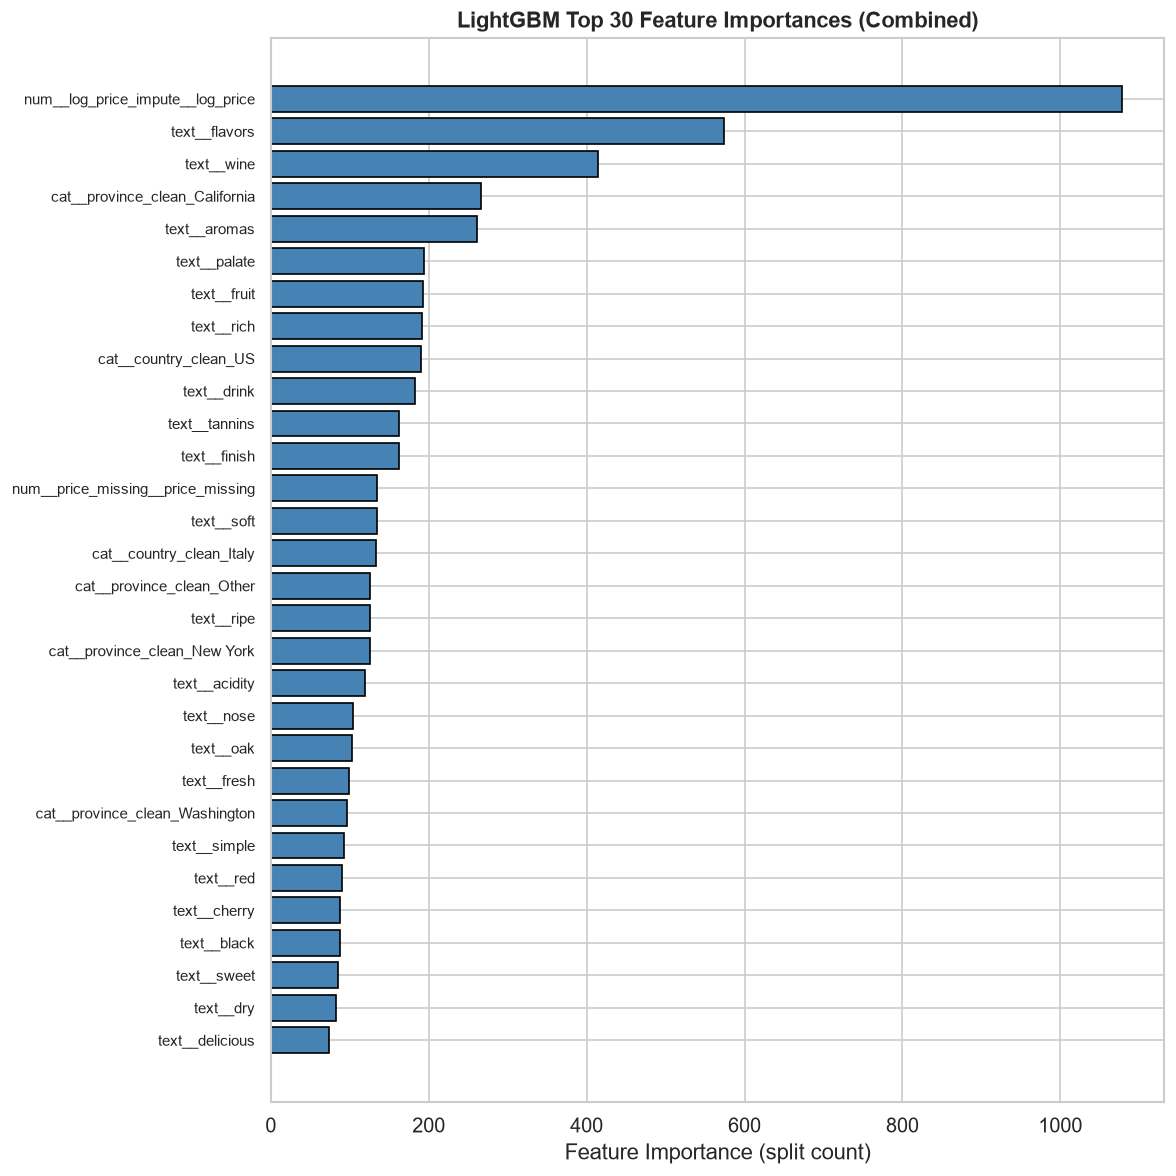

In [27]:
# Extract LightGBM feature importances
lgbm_model = pipes_combined['LightGBM'].named_steps['model']
ct_combined = pipes_combined['LightGBM'].named_steps['preprocess']
feat_names_all = ct_combined.get_feature_names_out()

importances = lgbm_model.feature_importances_
imp_df = pd.DataFrame({
    'feature': feat_names_all,
    'importance': importances
}).sort_values('importance', ascending=False)

# Top 30 features
top30 = imp_df.head(30)

fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(range(len(top30)), top30['importance'].values, color='steelblue', edgecolor='black')
ax.set_yticks(range(len(top30)))
ax.set_yticklabels(top30['feature'].values, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Feature Importance (split count)')
ax.set_title('LightGBM Top 30 Feature Importances (Combined)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'lgbm_feature_importance.png'))
plt.show()

print('Top 10 most important features:')
print(imp_df.head(10).to_string(index=False))

## 16. Actual vs Predicted Scatter Plot

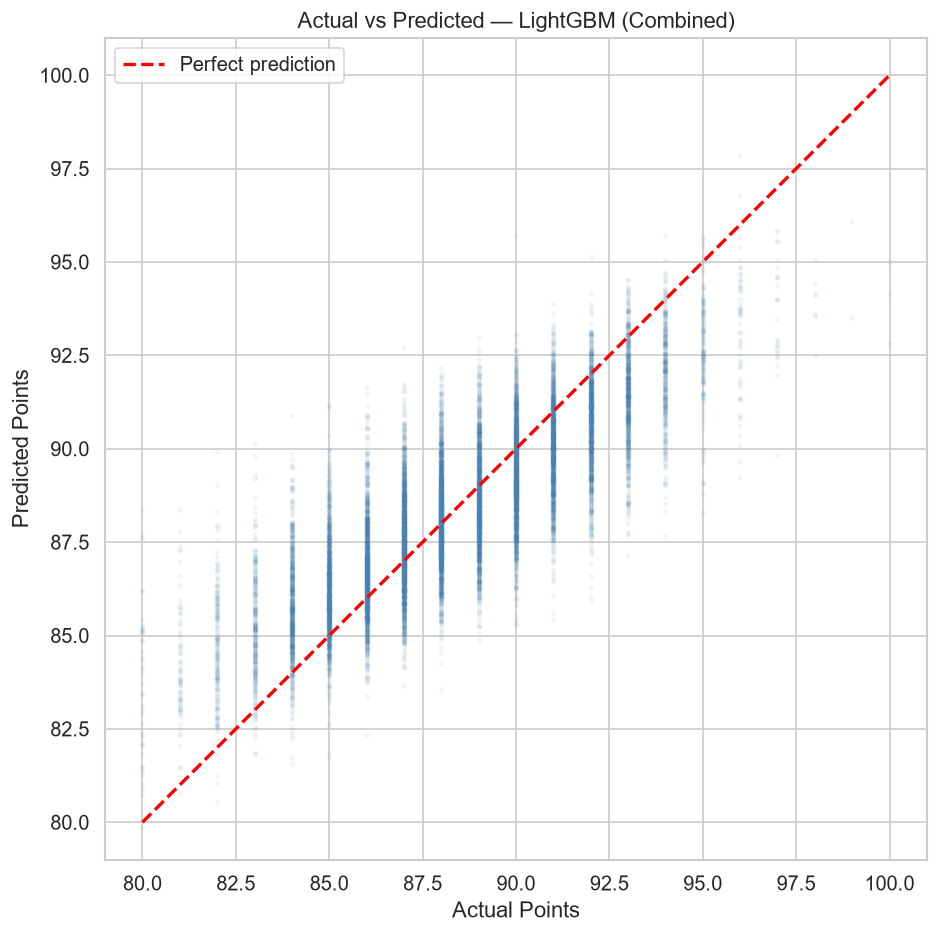

In [28]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, y_pred_best, alpha=0.05, s=5, color='steelblue')
ax.plot([80, 100], [80, 100], 'r--', linewidth=2, label='Perfect prediction')
ax.set_xlabel('Actual Points')
ax.set_ylabel('Predicted Points')
ax.set_title('Actual vs Predicted — LightGBM (Combined)')
ax.set_xlim(79, 101)
ax.set_ylim(79, 101)
ax.legend()
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'actual_vs_predicted.png'))
plt.show()

## 17. Summary & Conclusions

| Aspect | Finding |
|--------|---------|
| **Best Model** | LightGBM (Combined) achieves the lowest MAE and highest R² |
| **Text Contribution** | Tasting notes are the most informative feature group |
| **Price Contribution** | log(price) is the single most important metadata feature |
| **Extreme Scores** | 80–84 and 95–100 bands have highest MAE (regression to the mean) |
| **De-duplication** | Essential — duplicates leak test data into training |
| **Positive Words** | "complex", "elegant", "beautiful" push scores up |
| **Negative Words** | "simple", "thin", "short" push scores down |

### Key Takeaways:

1. **NLP features dominate** in this task because tasting notes are written to justify 
   the score — they essentially encode the reviewer's judgment in natural language.
   
2. **Price is a strong but imperfect proxy** for quality (r ≈ 0.42 with points). 
   Expensive wines score higher *on average*, but there's enormous variance.

3. **Gradient boosting handles mixed feature types** well. LightGBM captures nonlinear 
   interactions between TF-IDF features and metadata that linear models miss.

4. **Data hygiene matters**: de-duplicating before splitting is a fundamental ML 
   practice that prevents inflated evaluation metrics.

---
*Notebook by Muhammad Ahmad (70177776) — AI-101, The University of Lahore*